# Lab 4. Convolutional Neural Network (CNN)

## Setup

In [1]:
import kagglehub
path = kagglehub.dataset_download("puneet6060/intel-image-classification")

Using Colab cache for faster access to the 'intel-image-classification' dataset.


In [2]:
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_DIR = path

def find_dir(name):
    nested = os.path.join(DATA_DIR, name, name)
    flat = os.path.join(DATA_DIR, name)
    return nested if os.path.isdir(nested) else flat

TRAIN_DIR = find_dir("seg_train")
TEST_DIR = find_dir("seg_test")
print("Train dir:", TRAIN_DIR)
print("Test dir: ", TEST_DIR)
print("TensorFlow:", tf.__version__)

Train dir: /kaggle/input/intel-image-classification/seg_train/seg_train
Test dir:  /kaggle/input/intel-image-classification/seg_test/seg_test
TensorFlow: 2.21.0


## 1. Dataset Preparation
Steps: load the data, resize to 150 x 150, normalize to [0, 1], split `seg_train` into 80% train and 20% validation.

In [3]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32

# Load + resize to 150x150. The 80/20 split is done on seg_train only.
train_raw = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="training", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="int")

val_raw = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="validation", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="int")

test_raw = keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_raw.class_names
NUM_CLASSES = len(class_names)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.


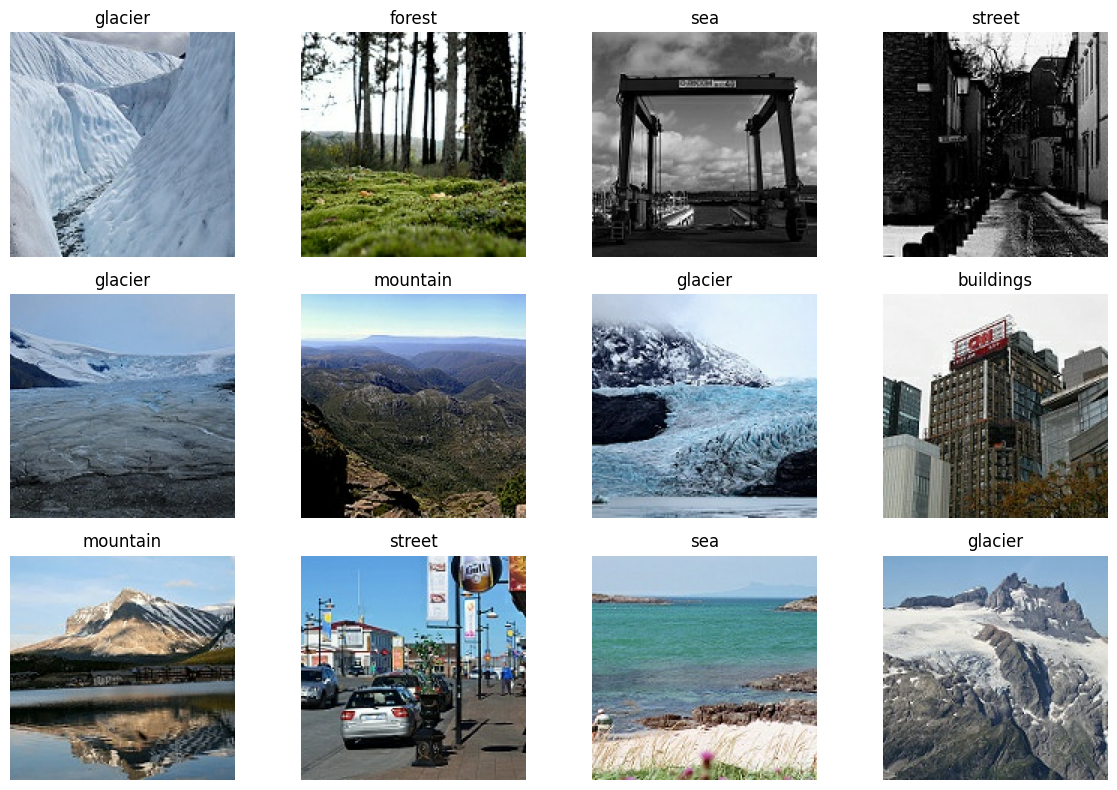

In [4]:
# Show example images (still raw 0-255 here)
images, labels = next(iter(train_raw))
plt.figure(figsize=(12, 8))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [5]:
# Report dataset sizes
n_train = len(train_raw.file_paths)
n_val = len(val_raw.file_paths)
n_test = len(test_raw.file_paths)

print(f"Number of training samples:   {n_train}")
print(f"Number of validation samples: {n_val}")
print(f"Number of test samples:       {n_test}")
print(f"Number of classes:            {NUM_CLASSES} -> {class_names}")

Number of training samples:   11228
Number of validation samples: 2806
Number of test samples:       3000
Number of classes:            6 -> ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [6]:
# Normalize to [0, 1] and build fast input pipelines
AUTOTUNE = tf.data.AUTOTUNE
normalize = layers.Rescaling(1.0 / 255)

def make_pipeline(ds, shuffle=False, augment=None):
    ds = ds.map(lambda x, y: (normalize(x), y), num_parallel_calls=AUTOTUNE)
    ds = ds.cache()
    if shuffle:
        ds = ds.shuffle(1000, seed=SEED)
    if augment is not None:
        # Augmentation runs after cache, so each epoch sees new variations
        ds = ds.map(lambda x, y: (augment(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_pipeline(train_raw, shuffle=True)
val_ds = make_pipeline(val_raw)
test_ds = make_pipeline(test_raw)

# Quick check of pixel range
x, y = next(iter(train_ds))
print("Batch shape:", x.shape)
print("Pixel range:", float(tf.reduce_min(x)), "to", float(tf.reduce_max(x)))

Batch shape: (32, 150, 150, 3)
Pixel range: 0.0 to 1.0


## Helper functions
Shared by all tasks so every model uses the same training settings.

In [7]:
EPOCHS = 30
LEARNING_RATE = 1e-3

results = {}        # test accuracy per task
settings = {}       # training settings per task (for the report)

def compile_model(model):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"])
    return model

def plot_history(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(history.history["accuracy"], label="train")
    ax[0].plot(history.history["val_accuracy"], label="validation")
    ax[0].set_title(f"{title}: accuracy")
    ax[0].set_xlabel("Epoch")
    ax[0].legend()
    ax[1].plot(history.history["loss"], label="train")
    ax[1].plot(history.history["val_loss"], label="validation")
    ax[1].set_title(f"{title}: loss")
    ax[1].set_xlabel("Epoch")
    ax[1].legend()
    plt.tight_layout()
    plt.show()

def evaluate_task(task_name, model, history, extra=""):
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    results[task_name] = test_acc
    settings[task_name] = {
        "Epochs run": len(history.history["loss"]),
        "Optimizer": f"Adam (lr={LEARNING_RATE})",
        "Loss": "SparseCategoricalCrossentropy (from_logits=True)",
        "Batch size": BATCH_SIZE,
        "Extra": extra,
    }
    print(f"{task_name} test accuracy: {test_acc:.4f}  (test loss: {test_loss:.4f})")

## 2. Build a CNN Model
Baseline: 1 Conv2D, 1 MaxPooling2D, 1 Flatten, Dense layers.

In [8]:
def build_baseline():
    return keras.Sequential([
        keras.Input(shape=(150, 150, 3)),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(NUM_CLASSES),          # logits
    ], name="task2_baseline")

model_t2 = compile_model(build_baseline())
model_t2.summary()

Model: "task2_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 175232)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │    11,214,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,216,198 (42.79 MB)

 Trainable params: 11,216,198 (42.79 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - accuracy: 0.5767 - loss: 1.1806 - val_accuracy: 0.6818 - val_loss: 0.8644
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.7690 - loss: 0.6554 - val_accuracy: 0.7327 - val_loss: 0.7850
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8758 - loss: 0.3759 - val_accuracy: 0.7359 - val_loss: 0.7920
Epoch 4/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9337 - loss: 0.2269 - val_accuracy: 0.6946 - val_loss: 1.0635
Epoch 5/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9699 - loss: 0.1176 - val_accuracy: 0.7391 - val_loss: 0.9630
Epoch 6/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9832 - loss: 0.0730 - val_accuracy: 0.7177 - val_loss: 1.1820
Epoch 7/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9869 - loss: 0.0614 - val_accuracy: 0.7195 - val_loss: 1.2573
Epoch 8/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9916 - loss: 0.0463 - val_acc

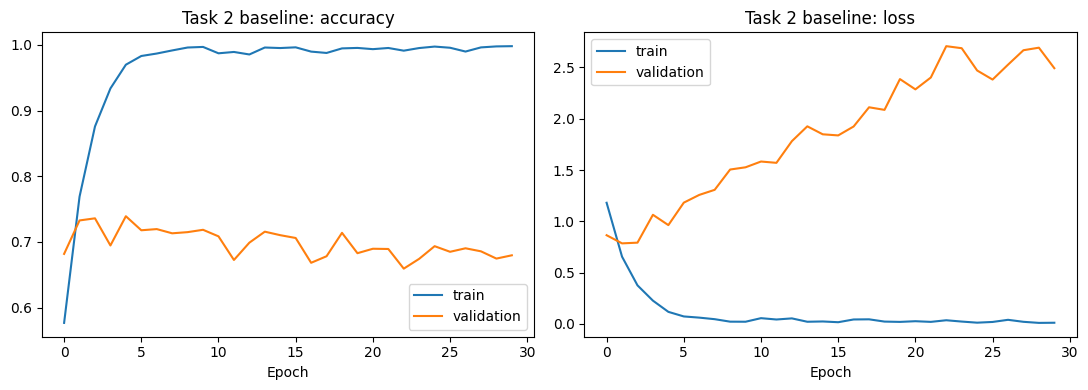

Task 2: Baseline CNN test accuracy: 0.6820  (test loss: 2.2654)


In [9]:
history_t2 = model_t2.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)
plot_history(history_t2, "Task 2 baseline")
evaluate_task("Task 2: Baseline CNN", model_t2, history_t2)

## 3. Modify the CNN Architecture
Changes: three Conv2D + MaxPooling2D blocks with more filters (32, 64, 128), and a larger Dense layer.

In [10]:
def build_deeper(name="task3_deeper"):
    return keras.Sequential([
        keras.Input(shape=(150, 150, 3)),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASSES),
    ], name=name)

model_t3 = compile_model(build_deeper())
model_t3.summary()

Model: "task3_deeper"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,126 (18.42 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 22s 44ms/step - accuracy: 0.6211 - loss: 0.9789 - val_accuracy: 0.7341 - val_loss: 0.7430
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7534 - loss: 0.6727 - val_accuracy: 0.7630 - val_loss: 0.7090
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.8044 - loss: 0.5308 - val_accuracy: 0.7691 - val_loss: 0.6402
Epoch 4/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.8531 - loss: 0.4040 - val_accuracy: 0.7965 - val_loss: 0.6061
Epoch 5/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.9039 - loss: 0.2783 - val_accuracy: 0.8019 - val_loss: 0.6861
Epoch 6/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.9346 - loss: 0.1834 - val_accuracy: 0.7726 - val_loss: 0.8269
Epoch 7/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.9575 - loss: 0.1268 - val_accuracy: 0.7919 - val_loss: 0.8571
Epoch 8/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.9710 - loss: 0.0856 - 

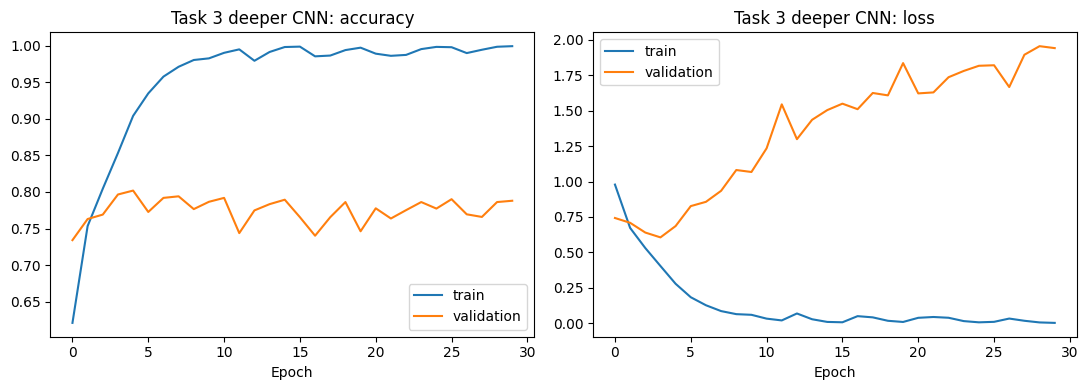

Task 3: Deeper CNN test accuracy: 0.7917  (test loss: 1.8817)


In [11]:
history_t3 = model_t3.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)
plot_history(history_t3, "Task 3 deeper CNN")
evaluate_task("Task 3: Deeper CNN", model_t3, history_t3,
              extra="3 conv blocks (32/64/128 filters)")

## 4. Data Augmentation
Augmentation is applied to the **training set only**. Validation and test sets stay untouched.
Methods: horizontal flip, rotation, zoom, brightness.

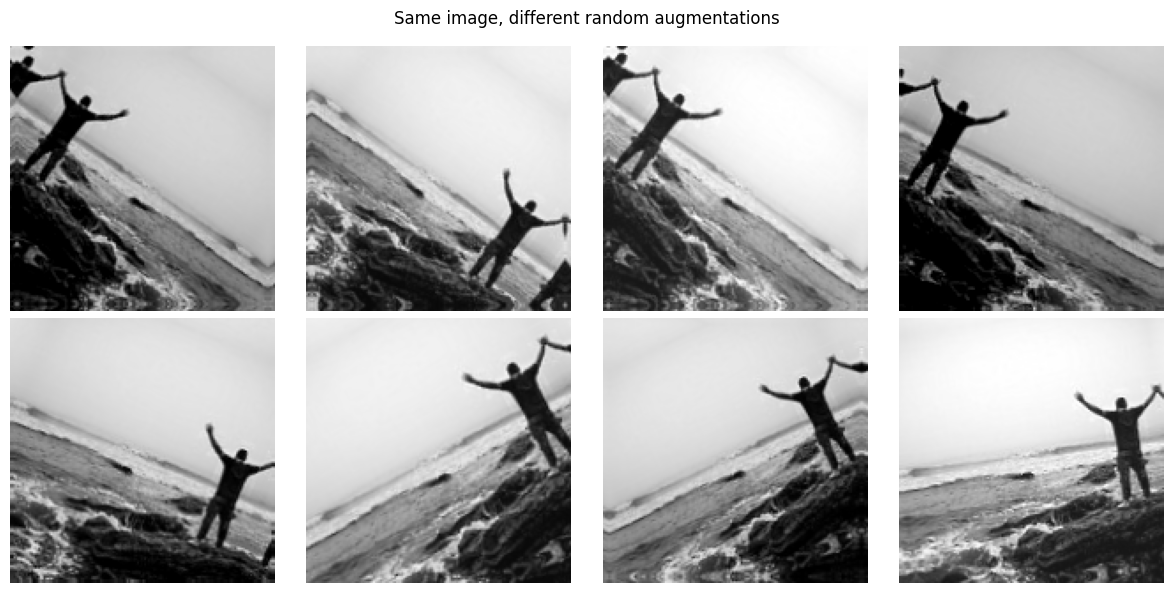

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),                             
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.1, value_range=(0.0, 1.0)),    
], name="data_augmentation")

# Preview
sample_x, _ = next(iter(train_ds))
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    aug = data_augmentation(sample_x[:1], training=True)
    plt.imshow(np.clip(aug[0].numpy(), 0, 1))
    plt.axis("off")
plt.suptitle("Same image, different random augmentations")
plt.tight_layout()
plt.show()

Epoch 1/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 69s 131ms/step - accuracy: 0.5728 - loss: 1.0933 - val_accuracy: 0.6878 - val_loss: 0.8414
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 59s 126ms/step - accuracy: 0.6838 - loss: 0.8406 - val_accuracy: 0.7341 - val_loss: 0.7263
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 44s 125ms/step - accuracy: 0.7299 - loss: 0.7363 - val_accuracy: 0.7787 - val_loss: 0.6161
Epoch 4/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 44s 126ms/step - accuracy: 0.7541 - loss: 0.6670 - val_accuracy: 0.7199 - val_loss: 0.7947
Epoch 5/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 45s 127ms/step - accuracy: 0.7737 - loss: 0.6160 - val_accuracy: 0.7901 - val_loss: 0.6057
Epoch 6/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 82s 126ms/step - accuracy: 0.7898 - loss: 0.5744 - val_accuracy: 0.8033 - val_loss: 0.5694
Epoch 7/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 82s 125ms/step - accuracy: 0.8009 - loss: 0.5380 - val_accuracy: 0.8072 - val_loss: 0.5498
Epoch 8/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 82s 125ms/step - accuracy: 0.8124 - loss: 0

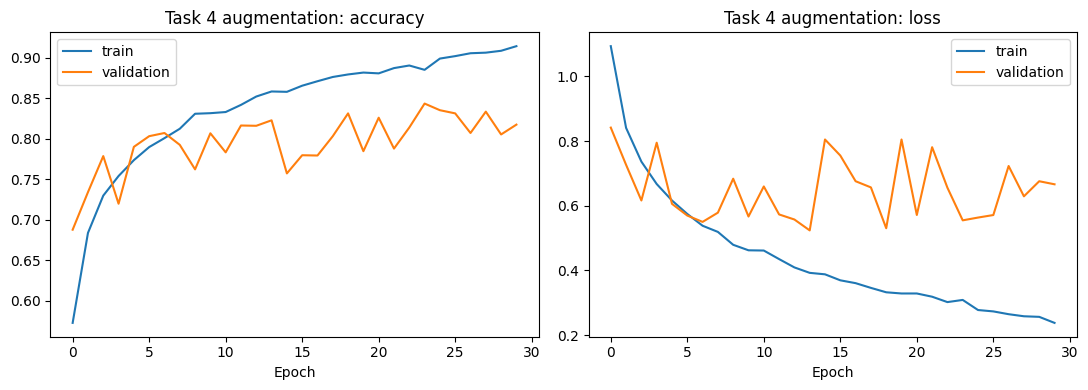

Task 4: Augmentation test accuracy: 0.8197  (test loss: 0.6625)


In [13]:
# Augmentation only on the training pipeline
train_ds_aug = make_pipeline(train_raw, shuffle=True, augment=data_augmentation)

model_t4 = compile_model(build_deeper(name="task4_augmentation"))
history_t4 = model_t4.fit(train_ds_aug, validation_data=val_ds, epochs=EPOCHS)
plot_history(history_t4, "Task 4 augmentation")
evaluate_task("Task 4: Augmentation", model_t4, history_t4,
              extra="Flip, rotation 0.1, zoom 0.1, brightness 0.1 (train only)")

## 5. Regularization
Dropout and EarlyStopping on top of the Task 4 setup (same architecture and augmentation).
EarlyStopping watches validation loss and restores the best weights. Max epochs is raised to 30 so early stopping has room to act.

In [14]:
def build_regularized(name="task5_regularized"):
    return keras.Sequential([
        keras.Input(shape=(150, 150, 3)),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dropout(0.3),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES),
    ], name=name)

model_t5 = compile_model(build_regularized())
model_t5.summary()

Model: "task5_regularized"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,126 (18.42 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 55s 143ms/step - accuracy: 0.5218 - loss: 1.2092 - val_accuracy: 0.6679 - val_loss: 0.8900
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 44s 126ms/step - accuracy: 0.6348 - loss: 0.9716 - val_accuracy: 0.7309 - val_loss: 0.7312
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 44s 126ms/step - accuracy: 0.6728 - loss: 0.8884 - val_accuracy: 0.7245 - val_loss: 0.7354
Epoch 4/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 44s 124ms/step - accuracy: 0.7001 - loss: 0.8099 - val_accuracy: 0.6835 - val_loss: 0.9283
Epoch 5/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 83s 129ms/step - accuracy: 0.7125 - loss: 0.7916 - val_accuracy: 0.7691 - val_loss: 0.6475
Epoch 6/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 81s 127ms/step - accuracy: 0.7327 - loss: 0.7368 - val_accuracy: 0.7498 - val_loss: 0.6781
Epoch 7/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 45s 126ms/step - accuracy: 0.7431 - loss: 0.7085 - val_accuracy: 0.7388 - val_loss: 0.7170
Epoch 8/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 45s 127ms/step - accuracy: 0.7501 - loss: 0

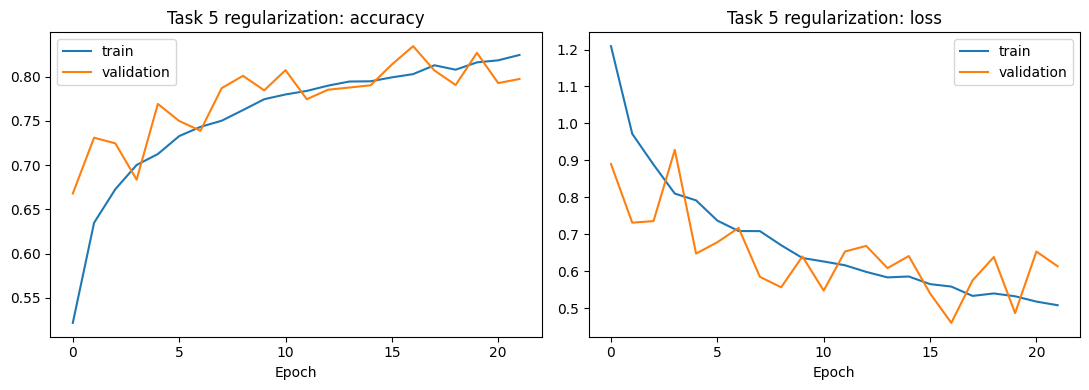

Task 5: Dropout + EarlyStopping test accuracy: 0.8383  (test loss: 0.4742)


In [15]:
EPOCHS_T5 = 30

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True)

history_t5 = model_t5.fit(
    train_ds_aug, validation_data=val_ds,
    epochs=EPOCHS_T5, callbacks=[early_stop])

plot_history(history_t5, "Task 5 regularization")
evaluate_task("Task 5: Dropout + EarlyStopping", model_t5, history_t5,
              extra="Dropout 0.3 and 0.5, EarlyStopping (patience=5), plus augmentation")

## Extension tasks (advanced techniques)
These cells go after Task 5 and use the data pipeline and dictionaries from the cells above.

- **Task 6:** improved custom CNN (BatchNorm, double conv blocks, GlobalAveragePooling, learning-rate scheduling).
- **Task 7:** transfer learning with MobileNetV2 (feature extraction, then fine-tuning).
- **Task 8:** error analysis (confusion matrix, per-class scores, wrong predictions).

No earlier function or variable is redefined. All new names start with `adv_` / `ADV_`, or are new model names (`model_t6`, `model_t7`).
`results` and `settings` are reused, so the Section 6 tables pick up the new tasks when you re-run them.

Augmentation here is placed **inside the model** (it only runs during training). This keeps it on the GPU, so it is much faster than the `tf.data` version used in Task 4. Validation and test data are not augmented.

### Extension helpers

In [16]:
ADV_EPOCHS = 40
ADV_LR = 1e-3
ADV_NAME_T6 = "Task 6: Improved CNN (BN + GAP)"
ADV_NAME_T7 = "Task 7: Transfer learning (MobileNetV2)"

def adv_compile(model, lr=ADV_LR):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"])
    return model

def adv_callbacks(patience=6, lr_patience=3):
    # New callback objects each call, so no state is shared between runs
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=lr_patience,
            min_lr=1e-6, verbose=1),
    ]

def adv_plot_history(histories, title, stage_names=None):
    # Accepts one History or a list of History objects (joined end to end)
    if not isinstance(histories, (list, tuple)):
        histories = [histories]
    merged = {k: [] for k in ("accuracy", "val_accuracy", "loss", "val_loss")}
    boundaries = []
    for h in histories:
        for k in merged:
            merged[k] += h.history[k]
        boundaries.append(len(merged["loss"]))
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for a, (tr, va, name) in zip(ax, [("accuracy", "val_accuracy", "accuracy"),
                                      ("loss", "val_loss", "loss")]):
        a.plot(merged[tr], label="train")
        a.plot(merged[va], label="validation")
        for b in boundaries[:-1]:
            a.axvline(b - 0.5, color="gray", linestyle="--", label="stage change")
        a.set_title(f"{title}: {name}")
        a.set_xlabel("Epoch")
        handles, labels = a.get_legend_handles_labels()
        uniq = dict(zip(labels, handles))
        a.legend(uniq.values(), uniq.keys())
    plt.tight_layout()
    plt.show()

def adv_record(task_name, model, epochs_run, optimizer_desc, extra=""):
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    results[task_name] = test_acc
    settings[task_name] = {
        "Epochs run": epochs_run,
        "Optimizer": optimizer_desc,
        "Loss": "SparseCategoricalCrossentropy (from_logits=True)",
        "Batch size": BATCH_SIZE,
        "Extra": extra,
    }
    print(f"{task_name} test accuracy: {test_acc:.4f}  (test loss: {test_loss:.4f})")

## 6. Improved custom CNN
Changes compared with Task 5:
- Two Conv2D layers per block (32, 64, 128, 256 filters), padding="same".
- BatchNormalization after each convolution, which makes training faster and more stable.
- GlobalAveragePooling2D instead of Flatten, which cuts the number of parameters a lot.
- Dropout after each block and before the output layer.
- ReduceLROnPlateau halves the learning rate when validation loss stops improving. EarlyStopping restores the best weights.
- Same augmentation as Task 4 (reused data_augmentation), applied only in training.

In [ ]:
def build_improved_cnn(name="task6_improved_cnn"):
    inputs = keras.Input(shape=(150, 150, 3))
    x = data_augmentation(inputs)                 # active only during training
    for filters in (32, 64, 128, 256):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Dropout(0.25)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES)(x)        
    return keras.Model(inputs, outputs, name=name)

model_t6 = adv_compile(build_improved_cnn())
model_t6.summary()

Model: "task6_improved_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 150, 150, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 150, 150, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 75, 75, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 75, 75, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 37, 37, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 37, 37, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,208,806 (4.61 MB)

 Trainable params: 1,206,886 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

Epoch 1/40
351/351 ━━━━━━━━━━━━━━━━━━━━ 68s 164ms/step - accuracy: 0.5321 - loss: 1.1684 - val_accuracy: 0.5834 - val_loss: 0.9633 - learning_rate: 0.0010
Epoch 2/40
351/351 ━━━━━━━━━━━━━━━━━━━━ 54s 154ms/step - accuracy: 0.6515 - loss: 0.9344 - val_accuracy: 0.6964 - val_loss: 0.8144 - learning_rate: 0.0010
Epoch 3/40
351/351 ━━━━━━━━━━━━━━━━━━━━ 54s 154ms/step - accuracy: 0.7050 - loss: 0.8061 - val_accuracy: 0.6796 - val_loss: 0.8031 - learning_rate: 0.0010
Epoch 4/40
351/351 ━━━━━━━━━━━━━━━━━━━━ 54s 155ms/step - accuracy: 0.7326 - loss: 0.7483 - val_accuracy: 0.5927 - val_loss: 1.2408 - learning_rate: 0.0010
Epoch 5/40
351/351 ━━━━━━━━━━━━━━━━━━━━ 54s 154ms/step - accuracy: 0.7483 - loss: 0.7012 - val_accuracy: 0.7053 - val_loss: 0.8316 - learning_rate: 0.0010
Epoch 6/40
351/351 ━━━━━━━━━━━━━━━━━━━━ 54s 155ms/step - accuracy: 0.7608 - loss: 0.6740 - val_accuracy: 0.7741 - val_loss: 0.6023 - learning_rate: 0.0010
Epoch 7/40
351/351 ━━━━━━━━━━━━━━━━━━━━ 54s 155ms/step - accuracy: 0.7

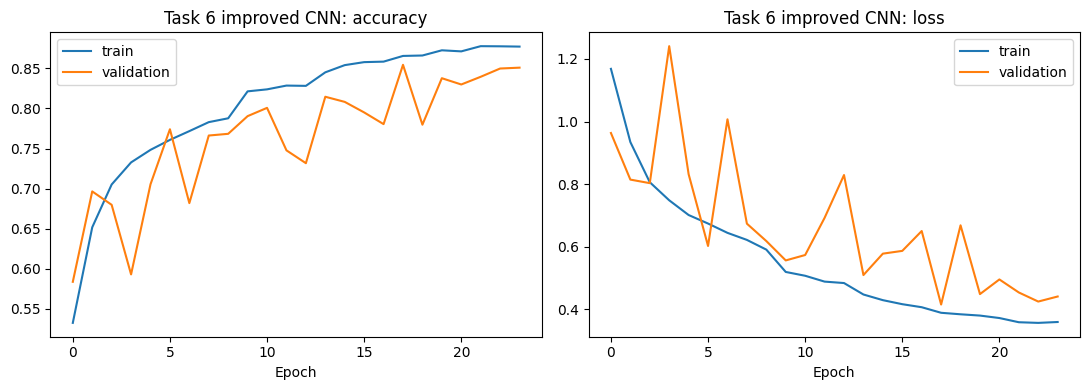

Task 6: Improved CNN (BN + GAP) test accuracy: 0.8423  (test loss: 0.4322)


In [18]:
history_t6 = model_t6.fit(
    train_ds, validation_data=val_ds,
    epochs=ADV_EPOCHS, callbacks=adv_callbacks())

adv_plot_history(history_t6, "Task 6 improved CNN")
adv_record(ADV_NAME_T6, model_t6,
           epochs_run=len(history_t6.history["loss"]),
           optimizer_desc=f"Adam (lr={ADV_LR}, ReduceLROnPlateau x0.5)",
           extra="BatchNorm, 2 conv per block (32-256), GAP, Dropout 0.25/0.5, augmentation, EarlyStopping")

## 7. Transfer learning (MobileNetV2)
A MobileNetV2 pretrained on ImageNet is used as the feature extractor.

- **Stage A, feature extraction:** the pretrained base is frozen. Only the new classifier head trains (lr = 1e-3).
- **Stage B, fine-tuning:** the last 30 layers of the base are unfrozen and trained with a very small learning rate (1e-5).

MobileNetV2 expects pixels in [-1, 1], so a Rescaling layer converts our [0, 1] images inside the model.

In [ ]:
def build_transfer_model(name="task7_mobilenetv2"):
    base = keras.applications.MobileNetV2(
        input_shape=(150, 150, 3), include_top=False, weights="imagenet")
    base.trainable = False

    inputs = keras.Input(shape=(150, 150, 3))
    x = data_augmentation(inputs)                       # training only
    x = layers.Rescaling(scale=2.0, offset=-1.0)(x)     # [0,1] -> [-1,1]
    x = base(x, training=False)                         # keep BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES)(x)              
    return keras.Model(inputs, outputs, name=name), base

model_t7, adv_base = build_transfer_model()
adv_compile(model_t7, lr=1e-3)
model_t7.summary()

/tmp/ipykernel_598/3033624590.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "task7_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [20]:
# Stage A: train the head only
ADV_EPOCHS_A = 10
history_t7a = model_t7.fit(
    train_ds, validation_data=val_ds,
    epochs=ADV_EPOCHS_A, callbacks=adv_callbacks(patience=4, lr_patience=2))

Epoch 1/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 19s 40ms/step - accuracy: 0.7585 - loss: 0.6807 - val_accuracy: 0.8806 - val_loss: 0.3319 - learning_rate: 0.0010
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.8484 - loss: 0.4322 - val_accuracy: 0.8813 - val_loss: 0.3252 - learning_rate: 0.0010
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.8581 - loss: 0.3883 - val_accuracy: 0.8988 - val_loss: 0.2815 - learning_rate: 0.0010
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.8625 - loss: 0.3837 - val_accuracy: 0.8760 - val_loss: 0.3423 - learning_rate: 0.0010
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.8665 - loss: 0.3690
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.8638 - loss: 0.3746 - val_accuracy: 0.8906 - val_loss: 0.2995 - learning_rate: 0.0010
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.8685 - los

Epoch 1/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 27s 51ms/step - accuracy: 0.8195 - loss: 0.4886 - val_accuracy: 0.9027 - val_loss: 0.2692 - learning_rate: 1.0000e-05
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 17s 47ms/step - accuracy: 0.8537 - loss: 0.3983 - val_accuracy: 0.9059 - val_loss: 0.2652 - learning_rate: 1.0000e-05
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - accuracy: 0.8685 - loss: 0.3637 - val_accuracy: 0.9070 - val_loss: 0.2590 - learning_rate: 1.0000e-05
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 16s 46ms/step - accuracy: 0.8750 - loss: 0.3407 - val_accuracy: 0.9052 - val_loss: 0.2622 - learning_rate: 1.0000e-05
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - accuracy: 0.8808 - loss: 0.3206 - val_accuracy: 0.9066 - val_loss: 0.2576 - learning_rate: 1.0000e-05
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - accuracy: 0.8893 - loss: 0.3053 - val_accuracy: 0.9052 - val_loss: 0.2595 - learning_rate: 1.0000e-05
Epoch 7/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step

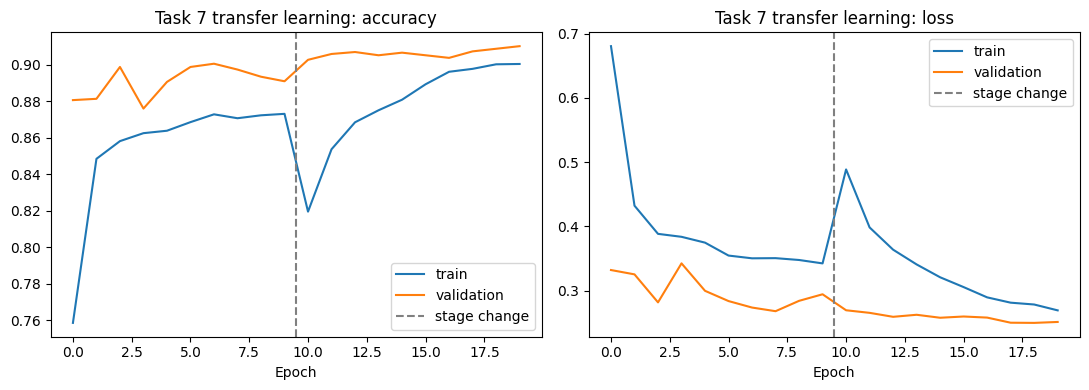

Task 7: Transfer learning (MobileNetV2) test accuracy: 0.9040  (test loss: 0.2514)


In [21]:
# Stage B: fine-tune the last 30 layers with a small learning rate
ADV_UNFREEZE = 30
ADV_EPOCHS_B = 10
ADV_LR_FT = 1e-5

adv_base.trainable = True
for layer in adv_base.layers[:-ADV_UNFREEZE]:
    layer.trainable = False

adv_compile(model_t7, lr=ADV_LR_FT)        # must recompile after changing trainable
history_t7b = model_t7.fit(
    train_ds, validation_data=val_ds,
    epochs=ADV_EPOCHS_B, callbacks=adv_callbacks(patience=4, lr_patience=2))

adv_plot_history([history_t7a, history_t7b], "Task 7 transfer learning")
adv_record(ADV_NAME_T7, model_t7,
           epochs_run=len(history_t7a.history["loss"]) + len(history_t7b.history["loss"]),
           optimizer_desc=f"Adam (lr=1e-3, then {ADV_LR_FT} for fine-tuning)",
           extra=f"MobileNetV2 (ImageNet), head first, then last {ADV_UNFREEZE} layers unfrozen, augmentation")

## 8. Error analysis
Uses the best model by test accuracy. Shows which classes get confused, then a few wrong predictions.

In [22]:
from sklearn.metrics import confusion_matrix, classification_report

adv_models = {
    "Task 2: Baseline CNN": model_t2,
    "Task 3: Deeper CNN": model_t3,
    "Task 4: Augmentation": model_t4,
    "Task 5: Dropout + EarlyStopping": model_t5,
    ADV_NAME_T6: model_t6,
    ADV_NAME_T7: model_t7,
}
adv_best_name = max(adv_models, key=lambda k: results[k])
adv_best_model = adv_models[adv_best_name]
print("Best model:", adv_best_name, f"(test accuracy {results[adv_best_name]:.4f})")

# test_ds is not shuffled, so labels and predictions line up
adv_y_true = np.concatenate([yb.numpy() for _, yb in test_ds])
adv_y_pred = np.argmax(adv_best_model.predict(test_ds, verbose=0), axis=1)

print()
print(classification_report(adv_y_true, adv_y_pred, target_names=class_names, digits=3))

Best model: Task 7: Transfer learning (MobileNetV2) (test accuracy 0.9040)

              precision    recall  f1-score   support

   buildings      0.865     0.950     0.905       437
      forest      0.983     0.992     0.987       474
     glacier      0.857     0.832     0.844       553
    mountain      0.854     0.827     0.840       525
         sea      0.924     0.955     0.939       510
      street      0.949     0.890     0.919       501

    accuracy                          0.904      3000
   macro avg      0.905     0.907     0.906      3000
weighted avg      0.904     0.904     0.904      3000



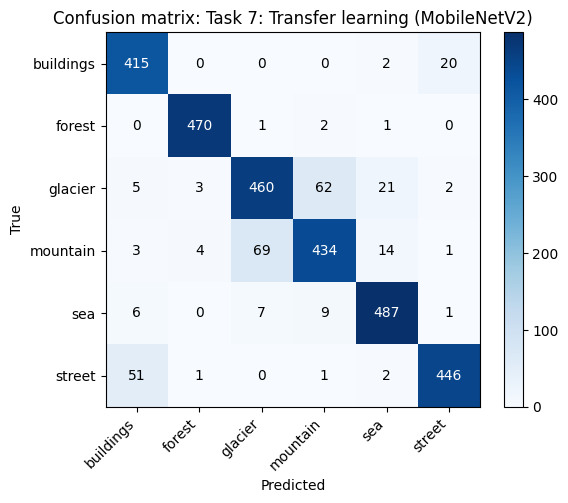

In [23]:
cm = confusion_matrix(adv_y_true, adv_y_pred)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=45, ha="right")
plt.yticks(range(NUM_CLASSES), class_names)
for adv_i in range(NUM_CLASSES):
    for adv_j in range(NUM_CLASSES):
        plt.text(adv_j, adv_i, cm[adv_i, adv_j], ha="center", va="center",
                 color="white" if cm[adv_i, adv_j] > cm.max() / 2 else "black")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"Confusion matrix: {adv_best_name}")
plt.tight_layout()
plt.show()

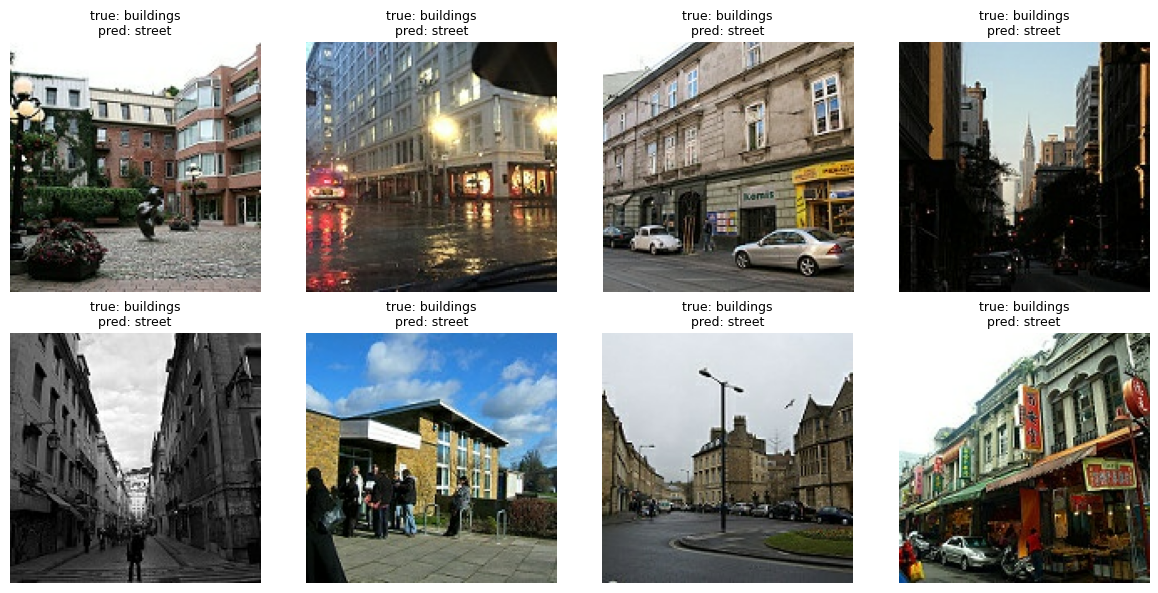

In [24]:
# Show up to 8 wrong predictions
adv_wrong = []
adv_idx = 0
for xb, yb in test_ds:
    preds = adv_y_pred[adv_idx: adv_idx + len(yb)]
    for adv_k in range(len(yb)):
        if preds[adv_k] != int(yb[adv_k]) and len(adv_wrong) < 8:
            adv_wrong.append((xb[adv_k].numpy(), int(yb[adv_k]), int(preds[adv_k])))
    adv_idx += len(yb)
    if len(adv_wrong) >= 8:
        break

plt.figure(figsize=(12, 6))
for adv_n, (adv_img, adv_t, adv_p) in enumerate(adv_wrong):
    plt.subplot(2, 4, adv_n + 1)
    plt.imshow(adv_img)
    plt.title(f"true: {class_names[adv_t]}\npred: {class_names[adv_p]}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

### After running the extension


In [25]:
adv_models_for_report = {
    "task6_improved_cnn": model_t6,
    "task7_mobilenetv2": model_t7,
}

os.makedirs("diagrams", exist_ok=True)
for adv_name, adv_m in adv_models_for_report.items():
    adv_path = f"diagrams/{adv_name}.png"
    try:
        keras.utils.plot_model(adv_m, to_file=adv_path, show_shapes=True,
                               show_layer_names=True, dpi=80)
        print("Saved", adv_path)
    except Exception as e:
        print(f"Could not draw {adv_name} ({type(e).__name__}). Showing summary instead.")
        adv_m.summary()

Saved diagrams/task6_improved_cnn.png
Saved diagrams/task7_mobilenetv2.png


## 6. Report material
Use the outputs below for your 1-page report.

### 6.1 Compare test accuracy (Tasks 2-5)

,Model,Test accuracy
0,Task 2: Baseline CNN,0.6820
1,Task 3: Deeper CNN,0.7917
2,Task 4: Augmentation,0.8197
3,Task 5: Dropout + EarlyStopping,0.8383
4,Task 6: Improved CNN (BN + GAP),0.8423
5,Task 7: Transfer learning (MobileNetV2),0.9040


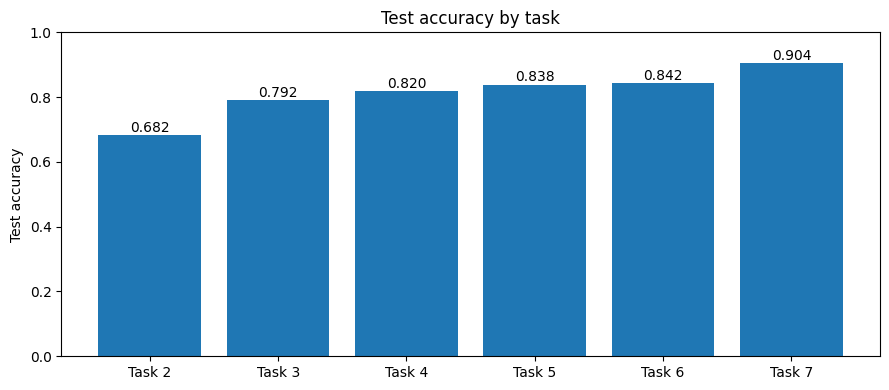

In [26]:
comparison = pd.DataFrame({
    "Model": list(results.keys()),
    "Test accuracy": [round(v, 4) for v in results.values()],
})
display(comparison)

plt.figure(figsize=(9, 4))
bars = plt.bar(range(len(results)), list(results.values()))
plt.xticks(range(len(results)), [k.split(":")[0] for k in results], rotation=0)
plt.ylim(0, 1)
plt.ylabel("Test accuracy")
plt.title("Test accuracy by task")
for b, v in zip(bars, results.values()):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center")
plt.tight_layout()
plt.show()

### 6.2 Training settings

In [27]:
display(pd.DataFrame(settings).T)

,Epochs run,Optimizer,Loss,Batch size,Extra
Task 2: Baseline CNN,30,Adam (lr=0.001),SparseCategoricalCrossentropy (from_logits=True),32,
Task 3: Deeper CNN,30,Adam (lr=0.001),SparseCategoricalCrossentropy (from_logits=True),32,3 conv blocks (32/64/128 filters)
Task 4: Augmentation,30,Adam (lr=0.001),SparseCategoricalCrossentropy (from_logits=True),32,"Flip, rotation 0.1, zoom 0.1, brightness 0.1 (..."
Task 5: Dropout + EarlyStopping,22,Adam (lr=0.001),SparseCategoricalCrossentropy (from_logits=True),32,"Dropout 0.3 and 0.5, EarlyStopping (patience=5..."
Task 6: Improved CNN (BN + GAP),24,"Adam (lr=0.001, ReduceLROnPlateau x0.5)",SparseCategoricalCrossentropy (from_logits=True),32,"BatchNorm, 2 conv per block (32-256), GAP, Dro..."
Task 7: Transfer learning (MobileNetV2),20,"Adam (lr=1e-3, then 1e-05 for fine-tuning)",SparseCategoricalCrossentropy (from_logits=True),32,"MobileNetV2 (ImageNet), head first, then last ..."


### 6.3 Model architecture diagrams

In [28]:
models_for_report = {
    "task2_baseline": model_t2,
    "task3_deeper": model_t3,
    "task4_augmentation": model_t4,
    "task5_regularized": model_t5,
}

os.makedirs("diagrams", exist_ok=True)
for name, m in models_for_report.items():
    path = f"diagrams/{name}.png"
    try:
        keras.utils.plot_model(m, to_file=path, show_shapes=True,
                               show_layer_names=True, dpi=80)
        print("Saved", path)
    except Exception as e:
        print(f"Could not draw {name} ({type(e).__name__}). Showing summary instead.")
        m.summary()

Saved diagrams/task2_baseline.png
Saved diagrams/task3_deeper.png
Saved diagrams/task4_augmentation.png
Saved diagrams/task5_regularized.png
